<a href="https://colab.research.google.com/github/karquiza/bikeshare-toronto-demand/blob/main/notebooks/00_init_explore.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# MAI103 - Data Science for Artificial Intelligence
# Group 11
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Load sample month from shared folder
import pandas as pd

DATA = '/content/drive/MyDrive/00_SENECA_FALL2026/MAI103-DATASCIENCE/MAI103-GroupProject/DataSets/raw'
df = pd.read_csv(f'{DATA}/2024/bikeshare-ridership-2024-01_Jan.csv')
df.head()

,Trip_Id,Trip_Duration,Start_Station_Id,Start_Time,Start_Station_Name,End_Station_Id,End_Time,End_Station_Name,Bike_Id,User_Type,Bike_Model
0,26682740,528,7041,2024-01-01 00:00:08,Edward St / Yonge St,7130.0,2024-01-01 00:08:56,Davenport Rd / Bedford Rd,7855,Casual,EFIT G5
1,26682742,1924,7245,2024-01-01 00:02:04,Tecumseth St / Queen St W - SMART,7259.0,2024-01-01 00:34:08,Lower Spadina Ave / Lake Shore Blvd W,2453,Casual,ICONIC
2,26682743,2741,7052,2024-01-01 00:03:25,Wellington St W / Bay St,7366.0,2024-01-01 00:49:06,Fort York Blvd / Bathurst St - SMART,7332,Member,ICONIC
3,26682744,353,7041,2024-01-01 00:03:39,Edward St / Yonge St,7418.0,2024-01-01 00:09:32,College Park - Yonge St Entrance,782,Member,ICONIC
4,26682746,2118,7721,2024-01-01 00:04:44,Widmer St / King St W,7721.0,2024-01-01 00:40:02,Widmer St / King St W,1008,Member,ICONIC


In [ ]:
df.shape, df.size

((204879, 11), 2253669)

In [ ]:
df.isna().sum()

,0
Trip_Id,0
Trip_Duration,0
Start_Station_Id,0
Start_Time,0
Start_Station_Name,0
End_Station_Id,89
End_Time,4
End_Station_Name,89
Bike_Id,0
User_Type,0


In [ ]:
df_explore = df.copy()

In [ ]:
pd.set_option("display.float_format", "{:,.0f}".format)

In [ ]:
trip_duration = df_explore["Trip_Duration"]
trip_duration.describe()

,Trip_Duration
count,"204,879"
mean,901
std,"10,293"
min,0
25%,361
50%,574
75%,917
max,"2,320,126"


**Observations:**
1. minimum Trip_Duration = 0 : To check if these are at the same station (Start_Station_Id == End_Station_Id?)
2. max Trip_Duration = 2,320,126 : Very far from the value at 75% (so most likely an outlier?)

In [ ]:
#trip_duration.value_counts().sort_index()

df_explore[df_explore["Trip_Duration"] > 2000].sort_values("Trip_Duration", ascending=False)

,Trip_Id,Trip_Duration,Start_Station_Id,Start_Time,Start_Station_Name,End_Station_Id,End_Time,End_Station_Name,Bike_Id,User_Type,Bike_Model
135296,26837460,2320126,7269,2024-01-23 20:48:25,Toronto Eaton Centre (Yonge St) - SMART,"7,428",2024-02-19 17:17:11,Woodbine Ave / Lake Shore Blvd E,3914,Casual,ICONIC
119140,26818864,1580918,7671,2024-01-21 09:55:41,Yonge St / Montgomery Ave - SMART,"7,376",2024-02-08 17:04:19,Frobisher Ave / Lascelles Blvd,3706,Member,ICONIC
31570,26718463,1444010,7900,2024-01-05 20:04:59,Simcoe St / Elm St,"7,788",2024-01-22 13:11:49,Queens Quay E / Lower Jarvis St,540,Member,ICONIC
59239,26750557,1181645,7257,2024-01-10 18:35:20,Dundas St W / St. Patrick St,"7,163",2024-01-24 10:49:25,Yonge St / Wood St,5328,Member,ICONIC
98709,26795527,1109336,7022,2024-01-17 17:18:10,Simcoe St / Queen St W,"7,100",2024-01-30 13:27:06,Dundas St E / Regent Park Blvd,1722,Casual,ICONIC
...,...,...,...,...,...,...,...,...,...,...,...
18674,26703905,2001,7447,2024-01-04 08:33:49,Trent Ave / Danforth Ave,"7,332",2024-01-04 09:07:10,200 Bloor St E,7896,Member,EFIT G5
115032,26814212,2001,7713,2024-01-20 11:37:31,Temperance St / Bay St,"7,019",2024-01-20 12:10:52,Temperance St Station,3736,Member,ICONIC
66364,26758722,2001,7006,2024-01-11 18:03:42,Bay St / College St (East Side),"7,061",2024-01-11 18:37:03,Dalton Rd / Bloor St W,5920,Member,ICONIC
21158,26706753,2001,7118,2024-01-04 14:50:01,King St W / Bay St (East Side),"7,076",2024-01-04 15:23:22,York St / Queens Quay W,3500,Member,ICONIC


In [ ]:
9012 / 204879

0.043986938632070635

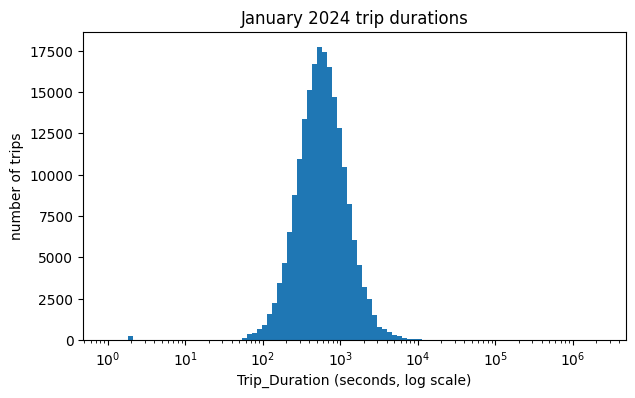

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
bins = np.logspace(0, np.log10(trip_duration.max()), 100)

plt.figure(figsize=(7, 4))
plt.hist(trip_duration[trip_duration > 0], bins=bins)
plt.xscale("log")
plt.xlabel("Trip_Duration (seconds, log scale)")
plt.ylabel("number of trips")
plt.title("January 2024 trip durations")
plt.show()

In [ ]:
trip